# 06 · 短训练、曲线与 checkpoint

## 学习目标

运行完整 PPO 管线，读取训练 CSV 和 checkpoint。256 步只用于执行验收，不能据此判断收敛。

本 Notebook 直接运行已补全的 exercise 实现；修改 `.py` 后重新运行相关 Cell。

## 环境准备

先按 [使用指南](README.md) 安装 `.[dev,notebook]`，选择项目 Kernel。

In [1]:
from pathlib import Path
import os
import sys
import torch
import numpy as np

# 从仓库根目录或 notebooks/ 打开都可；不要依赖某台机器的绝对路径。
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'pyproject.toml').exists()
                     and (p / 'src/ppo_pendulum').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目目录启动 JupyterLab')
os.chdir(PROJECT_ROOT)
%load_ext autoreload
%autoreload 2
torch.manual_seed(7)
np.random.seed(7)
print('Python:', sys.executable)
print('Project:', PROJECT_ROOT.name)

Python: /Users/matt/Documents/Codex/2026-11-15/referenced-chatgpt-conversation-this-is-an-2/work/.venv/bin/python
Project: ppo-inverted-pendulum


## 1. 参数与短训练

输出写到 `runs/notebook/`。重复运行会覆盖同名输出；想保留实验时修改目录。默认只运行 256 步，学习收敛可后续尝试 20,000/200,000 步。

In [2]:
from ppo_pendulum.config import PPOConfig
from ppo_pendulum.exercises.trainer import train
from ppo_pendulum.evaluate import evaluate
config = PPOConfig(total_timesteps=25600, rollout_steps=1280,
                   update_epochs=2, minibatch_size=64, seed=7,
                   output_dir=PROJECT_ROOT / 'runs/notebook/exercise')
checkpoint_path = train(config)
assert checkpoint_path.exists()
print('checkpoint:', checkpoint_path.relative_to(PROJECT_ROOT))

step=   1280 actor=-0.0114 critic=9.3485 episodes=119


step=   2560 actor=-0.0146 critic=8.6577 episodes=226


step=   3840 actor=-0.0100 critic=16.0368 episodes=300


step=   5120 actor=-0.0093 critic=21.9411 episodes=359


step=   6400 actor=-0.0107 critic=27.8085 episodes=408


step=   7680 actor=-0.0113 critic=37.2568 episodes=442


... (10 outputs left out)

step=  21760 actor=-0.0032 critic=32.2187 episodes=629


step=  23040 actor=-0.0010 critic=21.7307 episodes=639


step=  24320 actor=-0.0033 critic=40.5413 episodes=648


step=  25600 actor=-0.0024 critic=30.3030 episodes=654
checkpoint: runs/notebook/exercise/final.pt


## 2. 读取 loss 与回报

每行对应一次 rollout/update；只有两个采样点的线段仅说明记录通畅，不足以说明训练趋势。

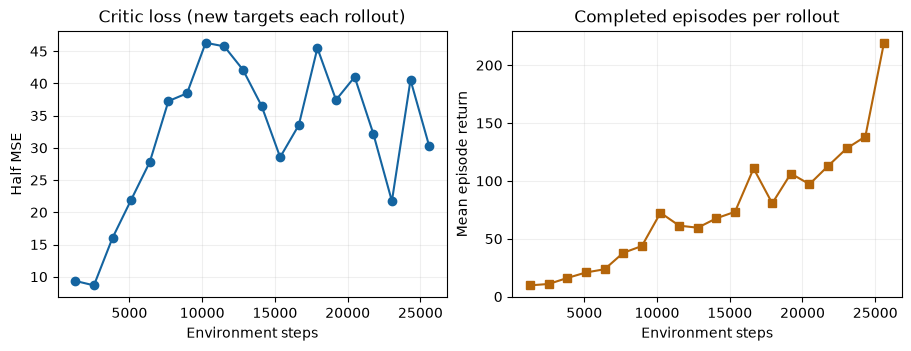

In [3]:
import csv
import matplotlib.pyplot as plt
with (config.output_dir / 'metrics.csv').open() as file:
    rows = list(csv.DictReader(file))
steps = [int(row['step']) for row in rows]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
axes[0].plot(steps, [float(row['critic_loss']) for row in rows], 'o-', color='#1464a0')
axes[0].set(title='Critic loss (new targets each rollout)', xlabel='Environment steps', ylabel='Half MSE')
returns = [float(row['mean_recent_return']) if row['mean_recent_return'] else np.nan for row in rows]
axes[1].plot(steps, returns, 's-', color='#b4650a')
axes[1].set(title='Completed episodes per rollout', xlabel='Environment steps', ylabel='Mean episode return')
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()
assert len(rows) == (config.total_timesteps + config.rollout_steps - 1) // config.rollout_steps

### 为什么 Critic loss 可能上升？

每个点都来自新策略采集的新 rollout，GAE advantage 和 Critic target
`y_t = V_old(s_t) + A_t` 也随之改变，因此这些 loss 不是同一固定数据集上的
连续误差。策略能维持更长回合时，未来奖励、target 的量级和方差通常都会变大，
绝对 MSE 可能上升或波动。

判断控制能力时优先看右图的平均回报和回合长度；同时检查 `approx_kl`、
`clip_fraction` 是否突然变大，以及 loss 是否出现 NaN/Inf。当前短训练中的
Critic loss 适合监控数值稳定性，不适合单独作为策略好坏的排序指标。


## 3. 重载 checkpoint 并评估

不打开图形窗口。评估使用均值动作，和训练时的随机采样策略不同。

In [4]:
mean_return, mean_length = evaluate(checkpoint_path, episodes=2, render=False)
print(f'mean_return={mean_return:.2f}, mean_length={mean_length:.1f}')
assert np.isfinite(mean_return) and 1 <= mean_length <= config.max_episode_steps

mean_return=309.00, mean_length=310.0


## 4. 录制并播放 MuJoCo 评估视频

下面用训练后 Actor 的确定性均值动作运行一个新回合。环境采用
`render_mode="rgb_array"`，`RecordVideo` 把画面写成 MP4，再由
Jupyter 内嵌播放器显示。视频最多录制 300 帧，避免 Notebook 文件过大；
训练过程本身不渲染，因此不会拖慢 PPO 数据采集。

In [5]:
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display
from ppo_pendulum.exercises.actor_critic import ExerciseActorCritic

saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
video_model = ExerciseActorCritic(
    saved["obs_dim"], saved["action_dim"], saved["config"]["hidden_size"]
)
video_model.load_state_dict(saved["model_state_dict"])
video_model.eval()

video_dir = config.output_dir / "videos"
video_prefix = f"exercise-step-{saved['global_step']}"
base_env = gym.make(
    config.env_id,
    render_mode="rgb_array",
    width=480,
    height=360,
    max_episode_steps=config.max_episode_steps,
)
video_env = RecordVideo(
    base_env,
    video_folder=str(video_dir),
    episode_trigger=lambda episode_id: episode_id == 0,
    video_length=300,
    name_prefix=video_prefix,
    disable_logger=True,
)

video_return = 0.0
video_length = 0
try:
    video_obs, _ = video_env.reset(seed=config.seed + 1_000)
    while True:
        obs_tensor = torch.as_tensor(video_obs, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            video_action = video_model.deterministic_action(obs_tensor)[0]
        video_action = torch.clamp(
            video_action,
            torch.as_tensor(video_env.action_space.low),
            torch.as_tensor(video_env.action_space.high),
        )
        video_obs, reward, terminated, truncated, _ = video_env.step(
            video_action.numpy()
        )
        video_return += float(reward)
        video_length += 1
        if terminated or truncated:
            break
finally:
    video_env.close()

video_files = sorted(
    video_dir.glob(f"{video_prefix}*.mp4"),
    key=lambda candidate: candidate.stat().st_mtime,
)
if not video_files:
    raise RuntimeError("视频没有生成，请确认已安装 .[notebook] 依赖")
video_path = video_files[-1]
print(
    f"evaluation return={video_return:.1f}, length={video_length}, "
    f"video={video_path.relative_to(PROJECT_ROOT)}"
)
display(Video(filename=str(video_path), embed=True, width=480))

/Users/matt/Documents/Codex/2026-11-15/referenced-chatgpt-conversation-this-is-an-2/work/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /Users/matt/Documents/Codex/2026-11-15/referenced-chatgpt-conversation-this-is-an-2/outputs/ppo-inverted-pendulum/runs/notebook/exercise/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


evaluation return=294.0, length=295, video=runs/notebook/exercise/videos/exercise-step-25600-episode-0.mp4


## 检查

这一页已经完整执行 exercise 工程：MuJoCo 环境采样、GAE、PPO
mini-batch 更新、CSV 记录、checkpoint 保存和重新载入评估。256 步只验证
管线；把 `total_timesteps` 调到 20,000 或 200,000 才适合观察学习效果。

## 下一步

完成练习实现，使用多个 seed 评估长期训练；保留 config 与 CSV，避免只观察单个最好结果。

公式对照：[PPO_FORMULAS.md](../docs/PPO_FORMULAS.md)。